# 03 · Regresión de ADR y Revenue Management
**Pregunta predictiva:** ¿qué ADR se observó históricamente según atributos de la reserva? **Pregunta comercial distinta:** ¿qué tarifa maximiza ingresos? La segunda requiere estimar demanda a distintos precios, algo que este dataset no identifica por sí solo.

In [31]:
# ============================================================
# PROYECTO: HOTEL REVENUE MANAGEMENT
# MODELO: REGRESIÓN PARA PREDICCIÓN DEL ADR
# ============================================================

# ------------------------------------------------------------
# 1. CONFIGURACIÓN DE RUTAS DEL PROYECTO
# ------------------------------------------------------------
# Permite ejecutar el notebook desde la raíz del proyecto
# hotel_yield_ml o desde la carpeta notebooks.

from pathlib import Path
import sys

ROOT = Path.cwd()

# Si no encuentra la carpeta src en la ubicación actual,
# busca en el directorio superior.
if not (ROOT / "src").exists():
    ROOT = ROOT.parent

# Verifica que estamos trabajando dentro del proyecto correcto.
assert (ROOT / "src").exists(), (
    "No se encontró la carpeta 'src'. "
    "Abre la carpeta hotel_yield_ml como proyecto en VS Code."
)

# Agrega src a las rutas de búsqueda de módulos de Python.
if str(ROOT / "src") not in sys.path:
    sys.path.insert(0, str(ROOT / "src"))


# ------------------------------------------------------------
# 2. IMPORTACIÓN DE LIBRERÍAS
# ------------------------------------------------------------

# Manipulación y análisis de datos
import numpy as np
import pandas as pd

# Visualización
import matplotlib.pyplot as plt

# Configuración de visualización de Pandas
pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 150)

# Funciones personalizadas del proyecto
from pipeline import (
    load_data,
    prepare,
    split_data,
    feature_columns,
    make_preprocessor
)

from regression import metrics

# Herramientas de Machine Learning
from sklearn.pipeline import Pipeline
from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestRegressor


# ------------------------------------------------------------
# 3. CARGA Y PREPARACIÓN DE LOS DATOS
# ------------------------------------------------------------

# Carga los datos originales.
raw = load_data()

# Ejecuta las transformaciones definidas en pipeline.py.
df = prepare(raw)

print("=" * 60)
print("CARGA DE DATOS")
print("=" * 60)

print(f"Registros originales: {len(raw):,}")
print(f"Registros preparados: {len(df):,}")


# ------------------------------------------------------------
# 4. FILTRADO DE RESERVAS VÁLIDAS
# ------------------------------------------------------------
# Para el modelo de ADR utilizaremos únicamente:
#
# - Reservas no canceladas.
# - ADR mayor o igual a 0.
# - ADR menor o igual a 1,000.
# - Reservas con al menos una noche.
#
# IMPORTANTE:
# Este filtro permite analizar tarifas de reservas realizadas,
# pero NO representa toda la demanda potencial del hotel.

df = df[
    (df["is_canceled"] == 0) &
    (df["adr"].between(0, 1000)) &
    (df["total_nights"] > 0)
].copy()

print("\n" + "=" * 60)
print("FILTRADO DE RESERVAS")
print("=" * 60)

print(f"Reservas válidas para el modelo ADR: {len(df):,}")
print(f"Reservas excluidas: {len(raw) - len(df):,} respecto a los datos originales")


# ------------------------------------------------------------
# 5. DIVISIÓN DE LOS DATOS
# ------------------------------------------------------------
# Separamos el dataset en tres conjuntos:
#
# TRAIN: entrenamiento del modelo.
# VAL:   validación y comparación de modelos.
# TEST:  evaluación final con datos no utilizados.
#
# La proporción depende de la función split_data()
# definida en pipeline.py.

train, val, test = split_data(df)

print("\n" + "=" * 60)
print("DISTRIBUCIÓN DE LOS DATOS")
print("=" * 60)

print(f"Entrenamiento : {len(train):,} registros")
print(f"Validación    : {len(val):,} registros")
print(f"Prueba        : {len(test):,} registros")
print(f"Total         : {len(df):,} registros")


# ------------------------------------------------------------
# 6. IDENTIFICACIÓN DE VARIABLES PREDICTORAS
# ------------------------------------------------------------
# La función feature_columns() identifica las columnas
# que serán utilizadas para predecir el ADR.
#
# El parámetro 'regression' indica que estamos trabajando
# con un problema de regresión.

cols = feature_columns(df, "regression")

print("\n" + "=" * 60)
print("VARIABLES PREDICTORAS")
print("=" * 60)

print(f"Cantidad de variables: {len(cols)}")

for i, col in enumerate(cols, start=1):
    print(f"{i:02d}. {col}")


# ------------------------------------------------------------
# 7. RESUMEN ESTADÍSTICO DEL ADR
# ------------------------------------------------------------
# Analizamos el comportamiento de la variable objetivo.

print("\n" + "=" * 60)
print("ESTADÍSTICAS DESCRIPTIVAS DEL ADR")
print("=" * 60)

print(df["adr"].describe().round(2))


# ------------------------------------------------------------
# 8. VALIDACIÓN FINAL
# ------------------------------------------------------------
# Verificamos que los conjuntos tengan registros y que
# las variables predictoras estén presentes.

assert len(df) > 0, "No existen registros después del filtrado."

assert all(len(data) > 0 for data in [train, val, test]), (
    "Uno de los conjuntos de entrenamiento, validación "
    "o prueba está vacío."
)

assert len(cols) > 0, "No se encontraron variables predictoras."

assert all(col in df.columns for col in cols), (
    "Existen variables predictoras que no están en el DataFrame."
)

print("\n" + "=" * 60)
print("PREPARACIÓN COMPLETADA CORRECTAMENTE")
print("=" * 60)


CARGA DE DATOS
Registros originales: 119,390
Registros preparados: 119,390

FILTRADO DE RESERVAS
Reservas válidas para el modelo ADR: 74,485
Reservas excluidas: 44,905 respecto a los datos originales

DISTRIBUCIÓN DE LOS DATOS
Entrenamiento : 44,691 registros
Validación    : 14,897 registros
Prueba        : 14,897 registros
Total         : 74,485 registros

VARIABLES PREDICTORAS
Cantidad de variables: 19
01. hotel
02. lead_time
03. stays_in_weekend_nights
04. stays_in_week_nights
05. adults
06. children
07. babies
08. meal
09. market_segment
10. distribution_channel
11. is_repeated_guest
12. previous_cancellations
13. previous_bookings_not_canceled
14. reserved_room_type
15. deposit_type
16. customer_type
17. arrival_month_num
18. total_nights
19. total_guests

ESTADÍSTICAS DESCRIPTIVAS DEL ADR
count    74485.00
mean       100.90
std         48.49
min          0.00
25%         68.00
50%         93.20
75%        125.10
max        510.00
Name: adr, dtype: float64

PREPARACIÓN COMPLETADA 

## 1 · Baseline: ¿es mejor que adivinar la mediana?
Para saber si ML agrega información necesitamos un comparador sencillo: predecir la mediana de ADR del conjunto de entrenamiento.

In [25]:
baseline=np.repeat(train.adr.median(),len(val))
print('Mediana train:',train.adr.median())
print('Baseline validación:',metrics(val.adr,baseline))


Mediana train: 93.17
Baseline validación: {'mae': 35.799169631469425, 'rmse': 48.723704887146916, 'r2': -0.02300278103256259}


## 2 · Ridge vs Random Forest
**Ridge** usa relaciones aproximadamente lineales y penaliza coeficientes altos. **Bosque** permite relaciones no lineales. Imputación, escala y OneHot se ajustan únicamente en train.

In [26]:
# ============================================================
# PROYECTO: HOTEL REVENUE MANAGEMENT
# MODELO: ENTRENAMIENTO Y EVALUACIÓN DE REGRESIÓN
# ALGORITMOS: RIDGE REGRESSION Y RANDOM FOREST
# ============================================================


# ------------------------------------------------------------
# 1. DEFINICIÓN DE LOS MODELOS
# ------------------------------------------------------------
# Utilizamos Pipeline para integrar dos procesos:
#
# prep  → Preprocesamiento de las variables predictoras.
# model → Algoritmo de Machine Learning.
#
# Esto garantiza que las transformaciones aprendidas durante
# el entrenamiento se apliquen también a los datos de validación.


models = {

    # --------------------------------------------------------
    # MODELO 1: RIDGE REGRESSION
    # --------------------------------------------------------
    # Regresión lineal con regularización L2.
    #
    # alpha=10:
    # Controla la intensidad de la regularización.
    # Valores mayores penalizan más los coeficientes.
    #
    # Es nuestro modelo de referencia (baseline).

    "Ridge": Pipeline([
        ("prep", make_preprocessor(train[cols])),
        ("model", Ridge(alpha=10))
    ]),


    # --------------------------------------------------------
    # MODELO 2: RANDOM FOREST REGRESSOR
    # --------------------------------------------------------
    # Algoritmo basado en múltiples árboles de decisión.
    #
    # n_estimators=100:
    # Construye 100 árboles de decisión.
    #
    # max_depth=16:
    # Limita la profundidad máxima de los árboles.
    #
    # min_samples_leaf=5:
    # Cada hoja debe contener al menos 5 observaciones.
    #
    # random_state=1:
    # Permite reproducir los resultados.
    #
    # n_jobs=-1:
    # Utiliza todos los núcleos disponibles del procesador.

    "Random Forest": Pipeline([
        ("prep", make_preprocessor(train[cols])),
        ("model", RandomForestRegressor(
            n_estimators=100,
            max_depth=16,
            min_samples_leaf=5,
            random_state=1,
            n_jobs=-1
        ))
    ])

}


# ------------------------------------------------------------
# 2. CREACIÓN DEL DICCIONARIO DE RESULTADOS
# ------------------------------------------------------------
# Almacenaremos las métricas de evaluación de cada modelo.

results = {}


# ------------------------------------------------------------
# 3. ENTRENAMIENTO Y VALIDACIÓN
# ------------------------------------------------------------
# Recorremos cada modelo y ejecutamos:
#
# 1. Entrenamiento con train.
# 2. Predicción sobre val.
# 3. Evaluación mediante la función metrics().
# 4. Almacenamiento de resultados.


print("=" * 65)
print("ENTRENAMIENTO Y EVALUACIÓN DE MODELOS")
print("=" * 65)


for name, model in models.items():

    print(f"\nEntrenando modelo: {name}")

    # Entrenamiento del modelo
    model.fit(
        train[cols],
        train["adr"]
    )

    # Predicción sobre datos de validación
    pred = model.predict(val[cols])

    # Cálculo de métricas
    results[name] = metrics(
        val["adr"],
        pred
    )

    # Mostrar resultados individuales
    print(f"Resultados de {name}:")
    print(results[name])


# ------------------------------------------------------------
# 4. TABLA COMPARATIVA DE RESULTADOS
# ------------------------------------------------------------
# Convertimos el diccionario de resultados en un DataFrame.
#
# Cada fila representa un modelo.
# Cada columna representa una métrica de evaluación.

df_results = pd.DataFrame(results).T

# Redondeamos a tres decimales.
df_results = df_results.round(3)


print("\n" + "=" * 65)
print("COMPARACIÓN DE MODELOS - VALIDACIÓN")
print("=" * 65)

display(df_results)


# ------------------------------------------------------------
# 5. FINALIZACIÓN
# ------------------------------------------------------------

print("\n" + "=" * 65)
print("ENTRENAMIENTO COMPLETADO")


ENTRENAMIENTO Y EVALUACIÓN DE MODELOS

Entrenando modelo: Ridge
Resultados de Ridge:
{'mae': 26.42524950082003, 'rmse': 36.309473297026805, 'r2': 0.43188519847623663}

Entrenando modelo: Random Forest
Resultados de Random Forest:
{'mae': 14.32448644408921, 'rmse': 22.572376985957593, 'r2': 0.7804412265252106}

COMPARACIÓN DE MODELOS - VALIDACIÓN


,mae,rmse,r2
Ridge,26.425,36.309,0.432
Random Forest,14.324,22.572,0.780



ENTRENAMIENTO COMPLETADO


## 3 · Interpretación de errores
**MAE:** distancia media en unidades monetarias; **RMSE:** penaliza más errores extremos; **R²:** comparación con predecir una media constante. Si R²<0, el modelo es peor que la referencia por media en esa partición.

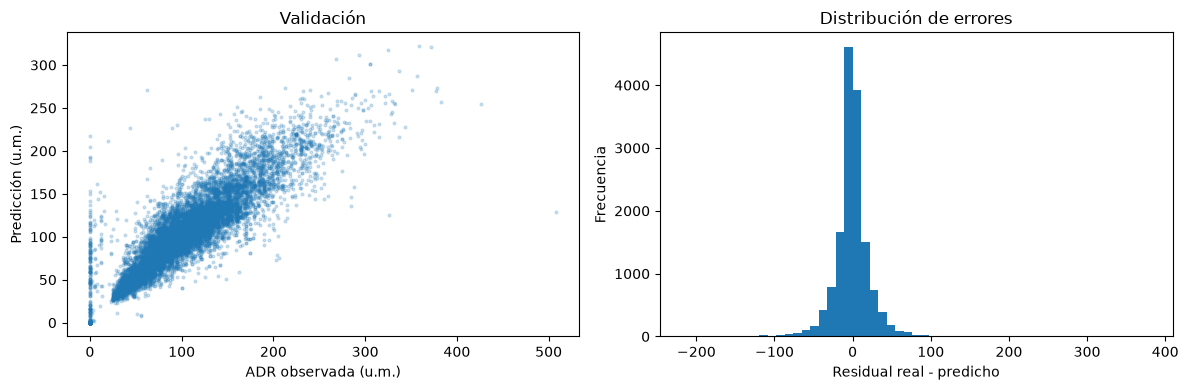

In [27]:
best=min(results,key=lambda n:results[n]['mae'])
pred=models[best].predict(val[cols]);err=val.adr.to_numpy()-pred
fig,axes=plt.subplots(1,2,figsize=(12,4))
axes[0].scatter(val.adr,pred,s=4,alpha=.2);axes[0].set(xlabel='ADR observada (u.m.)',ylabel='Predicción (u.m.)',title='Validación')
axes[1].hist(err,bins=55);axes[1].set(xlabel='Residual real - predicho',ylabel='Frecuencia',title='Distribución de errores')
plt.tight_layout();plt.show()

## 4 · Analizar el error por tipo de hotel
Un modelo puede funcionar bien en promedio y fallar sistemáticamente en un segmento; estudiar el MAE por hotel.

In [28]:
compare=val[['hotel','adr']].copy()
compare['pred']=pred;compare['error_abs']=(compare.adr-compare.pred).abs()
display(compare.groupby('hotel').agg(n=('adr','size'),adr_media=('adr','mean'),mae=('error_abs','mean')).round(2))

,n,adr_media,mae
hotel,,,
City Hotel,9206,105.78,13.80
Resort Hotel,5691,91.89,15.18


## 5 · Simulación conceptual de ingresos (NO optimización aprendida)
El precio óptimo no se deduce de un regresor ADR. Para **ilustrar** revenue management creamos probabilidades de venta totalmente supuestas. Son parámetros editables, NO predicciones entrenadas.

,tarifa_hipotetica_usd,probabilidad_venta_supuesta,ingreso_bruto_esperado_usd
0,80,0.90,2880.0
1,100,0.80,3200.0
2,120,0.62,2976.0
3,140,0.40,2240.0


Mayor ingreso bajo ESTOS SUPUESTOS: 100


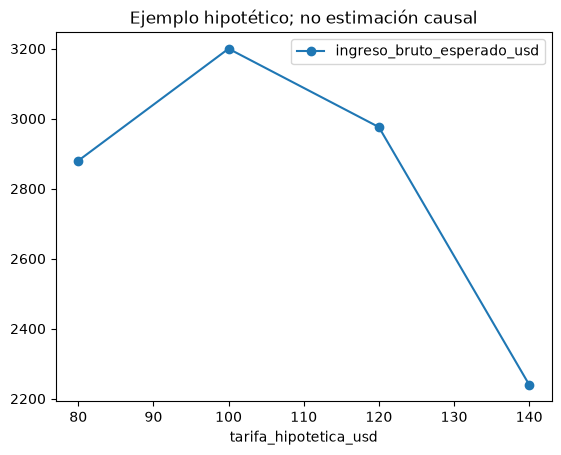

In [29]:
capacity=40
scenario=pd.DataFrame({'tarifa_hipotetica_usd':[80,100,120,140],
                       'probabilidad_venta_supuesta':[.90,.80,.62,.40]})
scenario['ingreso_bruto_esperado_usd']=capacity*scenario.tarifa_hipotetica_usd*scenario.probabilidad_venta_supuesta
display(scenario)
print('Mayor ingreso bajo ESTOS SUPUESTOS:',scenario.loc[scenario.ingreso_bruto_esperado_usd.idxmax(),'tarifa_hipotetica_usd'])
scenario.plot(x='tarifa_hipotetica_usd',y='ingreso_bruto_esperado_usd',marker='o',title='Ejemplo hipotético; no estimación causal');plt.show()

## 6 · Test: después de elegir en validación
El módulo replica exactamente la lógica, reentrena con train+val y evalúa una vez en test. Guarda el modelo y las métricas.

In [30]:
from regression import run
reporte,modelo_final=run()
print('Mejor modelo:',reporte['selected_model'],'TEST:',reporte['test'])

ridge {'mae': 26.425, 'rmse': 36.309, 'r2': 0.432}
random_forest {'mae': 14.324, 'rmse': 22.572, 'r2': 0.78}
Mejor modelo: random_forest TEST: {'mae': 14.314664929868597, 'rmse': 22.64358847468018, 'r2': 0.7836950815336778}


## 7 · Cierre de negocio
**Podemos afirmar:** el modelo predice ADR históricas con el error calculado sobre test.

**No podemos afirmar:** que elevar precios al ADR predicho maximizará RevPAR o ingresos. Tampoco tenemos curva de elasticidad.

**Para continuar:** incorporar visitas a la web sin compra, cotizaciones, precios mostrados, ocupación disponible por fecha, tarifas de competidores y costos; después validar políticas con pilotos medibles.